In [3]:
# @title Setup
import sys
from pathlib import Path

# Mount Drive
from google.colab import drive, userdata
drive.mount('/content/drive')
IN_COLAB = True

# Install the package securely from my branch
try:
    token = userdata.get('GITHUB_TOKEN')
    repo_url = f"git+https://{token}@github.com/parsa-hke/strokecopilot.git@benny/error-taxonomy"
    !pip install -q --force-reinstall {repo_url}
    print("Package installed successfully from benny/error-taxonomy.")
except Exception as e:
    print("Failed to install package. Check GITHUB_TOKEN in Colab Secrets and branch name.")
    raise e

import pandas as pd
import numpy as np
from strokecopilot.pipeline.compare import build_table

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Package installed successfully from benny/error-taxonomy.


In [4]:
# @title Configure Run Folders
# Add run folders here. Each tuple is (folder_path, metrics_file_name).

if IN_COLAB:
    BASE_DIR = Path('/content/drive/MyDrive/StrokeCopilot/runs')
else:
    BASE_DIR = Path('../runs')

RUN_FOLDERS = [
    (BASE_DIR / 'EXP-12_end_to_end_fixtures', 'metrics_phase3_judge_v3.json'),
]

In [7]:
# @title Build Pivoted Table
from strokecopilot.pipeline.compare import load_run

# 1. Load the raw runs
runs = [load_run(*f) for f in RUN_FOLDERS]

# 2. Build the raw flat table for the plotter
raw_table = []
for r in runs:
    row = {
        "model": r["model"],
        "source": r["source"],
        "arm": r["arm"],
    }
    for metric in ["hallucination_rate", "critical_hallucination_rate", "omission_rate"]:
        m = r["summary"].get(metric, {})
        row[metric] = m.get("value")
        row[f"{metric}_ci"] = m.get("ci95")
    raw_table.append(row)

# 3. Build the formatted DataFrame for display
rows = []
for r in runs:
    display_row = {"Model": r["model"]}
    source_arm = f"{r['source']} ({r['arm']})"

    for metric in ["hallucination_rate", "critical_hallucination_rate", "omission_rate"]:
        m = r["summary"].get(metric, {})
        val = m.get("value")
        ci = m.get("ci95")

        if val is None:
            formatted = "n/a"
        elif ci:
            formatted = f"{val:.3f} ({ci[0]:.3f}, {ci[1]:.3f})"
        else:
            formatted = f"{val:.3f}"

        display_row[(source_arm, metric.replace('_', ' ').title())] = formatted
    rows.append(display_row)

df = pd.DataFrame(rows).set_index("Model")
df.columns = pd.MultiIndex.from_tuples(df.columns)
display(df)

fixtures (with_rulebook)                                          
                        Hallucination Rate Critical Hallucination Rate Omission Rate
Model                                                                               
claude-sonnet-5-5                    0.054                       0.009         0.000

Figure saved to /content/drive/MyDrive/StrokeCopilot/runs/comparison/hallucination_comparison.png


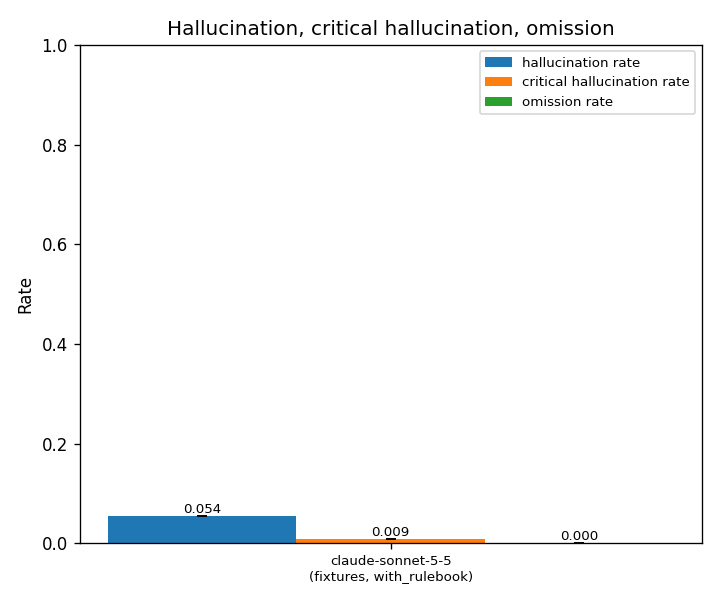

In [8]:
# @title Plot Figure
from strokecopilot.pipeline.compare import plot_table
import matplotlib.pyplot as plt
from IPython.display import Image

# Save to the runs folder, not inside a finished run
FIG_DIR = BASE_DIR / 'comparison'
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = FIG_DIR / 'hallucination_comparison.png'

# Generate the plot using the raw_table from Cell 3
plot_table(raw_table, OUT_PATH)
print(f"Figure saved to {OUT_PATH}")

# Display
if OUT_PATH.exists():
    display(Image(str(OUT_PATH)))

In [9]:
# @title Sanity Check lol
# Check that we have one row per model
models_in_table = list(df.index)
models_in_raw = list(set(r["model"] for r in raw_table))

assert len(models_in_table) == len(models_in_raw), "Error: Number of rows doesn't match number of models."
assert len(models_in_table) == len(set(models_in_table)), "Error: Duplicate models found in the table."

print(f"✓ Validation passed!")
print(f"✓ Table successfully built for {len(df)} model(s).")
print(f"✓ Data includes metrics for: {', '.join(df.columns.levels[0])}")

✓ Validation passed!
✓ Table successfully built for 1 model(s).
✓ Data includes metrics for: fixtures (with_rulebook)
